In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv(r"D:\HVIA\task2\Sharnouby_Enterprise\Sales_Transactions.csv")

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)




In [4]:
sales = df.dropna(
    subset=["Order_Date", "Invoice_ID", "Quantity"]
).copy()

sales = sales.sort_values("Order_Date")
sales.head()

,Row_ID,Invoice_ID,Order_Date,Month_Key,Location_ID,Location_Name,Channel,Customer_ID,Customer_Type,Customer_Governorate,...,Estimated_COGS_EGP,Gross_Profit_EGP,Gross_Margin_Pct,Payment_Method,Returned,Return_Date,Return_Reason,Refund_Value_EGP,Quality_Related_Return,Data_Class
130557,130557,INV0130558,2023-10-01,2023-10,LOC002,LEO MODA Online Store,Online,C24607,Retail,Alexandria,...,362.55,157.65,0.3031,Wallet,No,NaN,No return,0.00,No,Modeled training transaction anchored to publi...
98187,98187,INV0098188,2023-10-01,2023-10,LOC002,LEO MODA Online Store,Online,C10512,Retail,Beheira,...,623.60,474.40,0.4321,Card,No,NaN,No return,0.00,No,Modeled training transaction anchored to publi...
142465,142465,INV0142466,2023-10-01,2023-10,LOC001,LEO MODA - Sidi Bishr Store,Retail,C10012,Retail,Beheira,...,157.23,117.32,0.4273,Wallet,Yes,2023-10-13,Print issue,274.55,Yes,Modeled training transaction anchored to publi...
122380,122380,INV0122381,2023-10-01,2023-10,LOC001,LEO MODA - Sidi Bishr Store,Retail,C22969,Retail,Cairo,...,202.48,75.92,0.2727,Cash,No,NaN,No return,0.00,No,Modeled training transaction anchored to publi...
117828,117828,INV0117829,2023-10-01,2023-10,LOC002,LEO MODA Online Store,Online,C14317,Retail,Alexandria,...,956.68,595.32,0.3836,Cash,No,NaN,No return,0.00,No,Modeled training transaction anchored to publi...


In [5]:
unique_orders = sales["Invoice_ID"].nunique()

print(f"Total Unique Orders: {unique_orders:,}")


Total Unique Orders: 180,000


In [6]:

total_profit = sales["Gross_Profit_EGP"].sum()

print(f"Total Gross Profit: EGP {total_profit:,.2f}")


Total Gross Profit: EGP 64,888,289.90


In [7]:
sales["Year"] = sales["Order_Date"].dt.year

annual = (
    sales.groupby("Year")
    .agg(
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum")
    )
)

annual["Profit_Margin_Pct"] = (
    annual["Gross_Profit"]
    .div(annual["Net_Sales"].replace(0, np.nan))
    .mul(100)
)

annual = annual.reset_index()

annual_wide = pd.DataFrame()

for i, row in annual.iterrows():
    annual_wide[f"Year_{i+1}"] = [int(row["Year"])]
    annual_wide[f"Profit_{i+1}_EGP"] = [row["Gross_Profit"]]
    annual_wide[f"Margin_{i+1}_Pct"] = [row["Profit_Margin_Pct"]]

display(annual_wide.round(2))

,Year_1,Profit_1_EGP,Margin_1_Pct,Year_2,Profit_2_EGP,Margin_2_Pct,Year_3,Profit_3_EGP,Margin_3_Pct,Year_4,Profit_4_EGP,Margin_4_Pct
0,2023,5195405.18,15.88,2024,20584396.7,15.3,2025,21971520.39,15.38,2026,17136967.63,15.4


<Axes: xlabel='Channel', ylabel='count'>

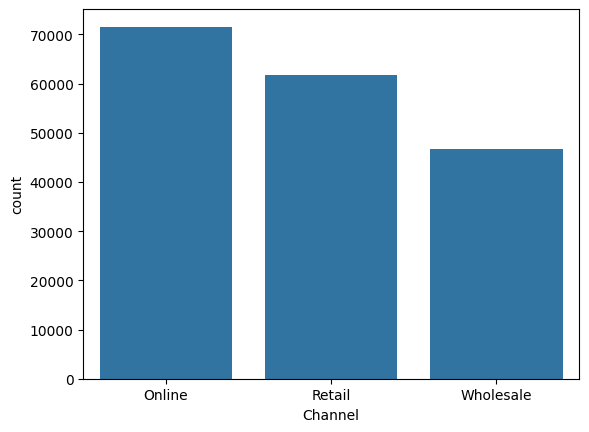

In [8]:
sns.countplot(x="Channel", data=sales)

In [9]:

import plotly.express as px

channel_profit = (
    sales.groupby("Channel", as_index=False)
    .agg(Gross_Profit=("Gross_Profit_EGP", "sum"))
    .sort_values("Gross_Profit", ascending=False)
)

fig = px.bar(
    channel_profit,
    x="Channel",
    y="Gross_Profit",
    title="Gross Profit by Channel",
    labels={
        "Channel": "Sales Channel",
        "Gross_Profit": "Gross Profit (EGP)"
    },
    text_auto=".2s"
)

fig.update_layout(
    xaxis_title="Channel",
    yaxis_title="Gross Profit (EGP)"
)

fig.show()


In [10]:

family_profit = (
    sales.groupby("Product_Family", as_index=False)
    .agg(
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum"),
        Quantity=("Quantity", "sum")
    )
    .sort_values("Gross_Profit", ascending=False)
)

display(family_profit.round(2))

fig = px.bar(
    family_profit,
    x="Product_Family",
    y="Gross_Profit",
    title="Gross Profit by Product Family",
    labels={
        "Product_Family": "Product Family",
        "Gross_Profit": "Gross Profit (EGP)"
    },
    text_auto=".2s"
)

fig.update_layout(xaxis_title="Product Family")
fig.show()


,Product_Family,Gross_Profit,Net_Sales,Quantity
1,Pajamas/Homewear,41184401.86,2.723290e+08,1176405
2,Sweatshirts,13725982.82,7.658352e+07,198807
0,Kids Sets,5274356.82,3.645309e+07,129980
3,T-Shirts,4703548.40,3.597278e+07,155397


In [11]:
product_profit = (
    sales.groupby(["Product_ID", "Product_Name"], as_index=False)
    .agg(
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum")
    )
    .sort_values("Gross_Profit", ascending=False)
)

top_10_products = product_profit.head(10).copy()

total_profit = sales["Gross_Profit_EGP"].sum()

top_10_profit = top_10_products["Gross_Profit"].sum()

top_10_share = (
    top_10_profit / total_profit * 100
    if total_profit != 0 else np.nan
)

print(f"Top 10 Products Gross Profit: EGP {top_10_profit:,.2f}")
print(f"Share of Total Gross Profit: {top_10_share:.2f}%")

fig = px.bar(
    top_10_products.sort_values("Gross_Profit"),
    x="Gross_Profit",
    y="Product_Name",
    orientation="h",
    title="Top 10 Products by Gross Profit",
    labels={
        "Gross_Profit": "Gross Profit (EGP)",
        "Product_Name": "Product"
    },
    hover_data=["Product_ID", "Net_Sales"],
    text_auto=".2s"
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()


Top 10 Products Gross Profit: EGP 25,513,134.69
Share of Total Gross Profit: 39.32%


In [12]:

family_size_profit = (
    sales.groupby(["Product_Family", "Size"], as_index=False)
    .agg(
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Quantity=("Quantity", "sum")
    )
)

fig = px.bar(
    family_size_profit,
    x="Product_Family",
    y="Gross_Profit",
    color="Size",
    barmode="group",
    title="Gross Profit by Size within Each Product Family",
    labels={
        "Product_Family": "Product Family",
        "Size": "Size",
        "Gross_Profit": "Gross Profit (EGP)"
    },
    hover_data=["Quantity"]
)

fig.show()


In [13]:

def to_bool(series):
    return (
        series.astype("string")
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes", "y"])
    )

sales["Returned_Flag"] = to_bool(sales["Returned"])
sales["Quality_Return_Flag"] = to_bool(
    sales["Quality_Related_Return"]
)

returned_rows = sales[sales["Returned_Flag"]].copy()

total_orders = sales["Invoice_ID"].nunique()

returned_orders = returned_rows["Invoice_ID"].nunique()

return_rate = (
    returned_orders / total_orders * 100
    if total_orders else np.nan
)

total_refund = returned_rows["Refund_Value_EGP"].sum()

quality_returned = returned_rows[
    returned_rows["Quality_Return_Flag"]
].copy()

quality_return_orders = quality_returned["Invoice_ID"].nunique()

quality_refund = quality_returned["Refund_Value_EGP"].sum()

quality_refund_share = (
    quality_refund / total_refund * 100
    if total_refund != 0 else np.nan
)

print(f"Total Unique Orders: {total_orders:,}")
print(f"Returned Unique Orders: {returned_orders:,}")
print(f"Return Rate: {return_rate:.2f}%")
print(f"Total Recorded Refund Value: EGP {total_refund:,.2f}")
print(f"Quality-Related Returned Orders: {quality_return_orders:,}")
print(f"Quality-Related Refund Value: EGP {quality_refund:,.2f}")
print(f"Quality Share of Refund Value: {quality_refund_share:.2f}%")


Total Unique Orders: 180,000
Returned Unique Orders: 8,543
Return Rate: 4.75%
Total Recorded Refund Value: EGP 9,427,005.55
Quality-Related Returned Orders: 2,457
Quality-Related Refund Value: EGP 2,509,899.21
Quality Share of Refund Value: 26.62%


In [14]:

quality_returns_by_family = (
    sales.groupby("Product_Family")
    .apply(
        lambda group: pd.Series({
            "Total_Sold_Quantity": group["Quantity"].sum(),
            "Quality_Returned_Quantity": group.loc[
                group["Returned_Flag"] & group["Quality_Return_Flag"],
                "Quantity"
            ].sum()
        }),
        include_groups=False
    )
    .reset_index()
)

quality_returns_by_family["Quality_Return_Pct"] = (
    quality_returns_by_family["Quality_Returned_Quantity"]
    .div(
        quality_returns_by_family["Total_Sold_Quantity"].replace(0, np.nan)
    )
    .mul(100)
)

quality_returns_by_family = quality_returns_by_family.sort_values(
    "Quality_Return_Pct",
    ascending=False
)

display(quality_returns_by_family.round(2))


,Product_Family,Total_Sold_Quantity,Quality_Returned_Quantity,Quality_Return_Pct
0,Kids Sets,129980,842,0.65
3,T-Shirts,155397,957,0.62
1,Pajamas/Homewear,1176405,6939,0.59
2,Sweatshirts,198807,1141,0.57


In [15]:
return_reasons = (
    sales[sales["Returned_Flag"]]
    .groupby("Return_Reason", dropna=False)
    .size()
    .reset_index(name="Return_Count")
    .sort_values("Return_Count", ascending=False)
)

return_reasons["Return_Reason"] = (
    return_reasons["Return_Reason"]
    .fillna("Unknown")
)

fig = px.bar(
    return_reasons,
    x="Return_Reason",
    y="Return_Count",
    title="Return Count by Return Reason",
    labels={
        "Return_Reason": "Return Reason",
        "Return_Count": "Number of Returns"
    },
    text="Return_Count"
)

fig.update_traces(textposition="outside")
fig.update_layout(
    xaxis_tickangle=-30,
    showlegend=False
)

fig.show()

In [16]:

sales["Month_Name"] = sales["Order_Date"].dt.month_name()
sales["Month_Number"] = sales["Order_Date"].dt.month

monthly_profit = (
    sales.groupby(["Month_Number", "Month_Name", "Year"], as_index=False)
    .agg(Gross_Profit=("Gross_Profit_EGP", "sum"))
)

profit_pivot = monthly_profit.pivot(
    index=["Month_Number", "Month_Name"],
    columns="Year",
    values="Gross_Profit"
)

# Number of distinct years in which each month appears
years_present = (
    monthly_profit.groupby("Month_Number")["Year"]
    .nunique()
    .rename("Years_Present")
)

month_analysis = profit_pivot.join(years_present)

month_analysis = (
    month_analysis.reset_index()
    .sort_values("Month_Number")
    .drop(columns="Month_Number")
)

display(month_analysis.round(2))


,Month_Name,2023,2024,2025,2026,Years_Present
0,January,NaN,1461991.42,1630475.37,1722416.57,3
1,February,NaN,1383406.49,1369113.84,1553435.58,3
2,March,NaN,1605080.00,1709726.64,1874987.37,3
3,April,NaN,1685023.12,1817229.51,1912359.06,3
4,May,NaN,1678468.53,1969804.32,2135185.38,3
5,June,NaN,1740982.49,1951774.22,2027719.60,3
6,July,NaN,1872945.74,2036493.24,2132404.38,3
7,August,NaN,1704408.23,1992141.53,2085752.26,3
8,September,NaN,1478124.60,1568056.50,1692707.43,3
9,October,1558433.72,1767654.12,1620892.83,NaN,3


In [17]:

month_profit_total = (
    monthly_profit.groupby("Month_Number", as_index=False)
    .agg(Gross_Profit=("Gross_Profit", "sum"))
    .sort_values("Month_Number")
)

month_profit_total["Month_Name"] = (
    month_profit_total["Month_Number"].map(
        dict(enumerate(
            ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
            start=1
        ))
    )
)

fig = px.bar(
    month_profit_total,
    x="Month_Name",
    y="Gross_Profit",
    title="Total Gross Profit by Calendar Month Across Available Years",
    labels={
        "Month_Name": "Month",
        "Gross_Profit": "Total Gross Profit (EGP)"
    },
    text_auto=".2s"
)

fig.update_layout(
    xaxis={
        "categoryorder": "array",
        "categoryarray": [
            "Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
        ]
    }
)

fig.show()


In [18]:
unique_skus = sales["SKU"].nunique()

print(f"Total Unique SKUs: {unique_skus:,}")


Total Unique SKUs: 59


In [19]:

available_years = sorted(
    sales["Order_Date"].dropna().dt.year.unique()
)

selected_years = available_years[-3:]

sales_3y = sales[
    sales["Order_Date"].dt.year.isin(selected_years)
].copy()

monthly_quantity = (
    sales_3y.groupby(["Year", "Month_Number"], as_index=False)
    .agg(Quantity=("Quantity", "sum"))
)

# Missing months remain NaN so gaps are not mistaken for zero sales.
full_index = pd.MultiIndex.from_product(
    [selected_years, range(1, 13)],
    names=["Year", "Month_Number"]
)

monthly_quantity = (
    monthly_quantity.set_index(["Year", "Month_Number"])
    .reindex(full_index)
    .reset_index()
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig = px.line(
    monthly_quantity,
    x="Month_Number",
    y="Quantity",
    color="Year",
    markers=True,
    title="Monthly Sales Quantity Across the Latest 3 Available Years",
    labels={
        "Month_Number": "Month",
        "Quantity": "Total Quantity Sold",
        "Year": "Year"
    }
)

fig.update_xaxes(
    tickmode="array",
    tickvals=list(range(1, 13)),
    ticktext=month_names
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Total Quantity Sold"
)

fig.show()


# modeling

In [20]:
DATA_START = pd.Period("2023-09", freq="M")
DATA_END = pd.Period("2026-09", freq="M")

TARGET = "Quantity"
DATE_COL = "Order_Date"
FORECAST_HORIZON = 3
FREQUENCY = "M"

EXPERIMENTS = {
    "A_Product_Family": "Product_Family",
    "B_SKU": "SKU"
}

# Prepare shared data
sales["Order_Date"] = pd.to_datetime(sales["Order_Date"], errors="coerce")
sales["Quantity"] = pd.to_numeric(sales["Quantity"], errors="coerce")

forecast_data = sales.loc[
    sales["Order_Date"].notna()
    & sales["Quantity"].notna()
    & sales["Product_Family"].notna()
    & sales["SKU"].notna()
].copy()

forecast_data["Month"] = forecast_data["Order_Date"].dt.to_period("M")

forecast_data = forecast_data.loc[
    forecast_data["Month"].between(DATA_START, DATA_END)
].copy()

print(f"Data Period: {DATA_START} to {DATA_END}")
print(f"Forecast Horizon: {FORECAST_HORIZON} months")
print(f"Target: {TARGET}")
print(f"Aggregation Levels: {list(EXPERIMENTS.keys())}")
print(f"Transactions Available: {len(forecast_data):,}")
print(f"Observed Months: {forecast_data['Month'].nunique()}")
print(f"First Observed Month: {forecast_data['Month'].min()}")
print(f"Last Observed Month: {forecast_data['Month'].max()}")

Data Period: 2023-09 to 2026-09
Forecast Horizon: 3 months
Target: Quantity
Aggregation Levels: ['A_Product_Family', 'B_SKU']
Transactions Available: 180,000
Observed Months: 36
First Observed Month: 2023-10
Last Observed Month: 2026-09


In [21]:

monthly_data = {}

for experiment_name, group_col in EXPERIMENTS.items():

    monthly = (
        forecast_data
        .groupby([group_col, "Month"], as_index=False)
        .agg(Quantity=("Quantity", "sum"))
        .sort_values([group_col, "Month"])
    )

    complete_series = []

    for item, group in monthly.groupby(group_col, sort=False):

        item_monthly = (
            group.set_index("Month")["Quantity"]
            .sort_index()
        )

        full_month_range = pd.period_range(
            start=item_monthly.index.min(),
            end=DATA_END,
            freq="M"
        )

        item_monthly = item_monthly.reindex(
            full_month_range,
            fill_value=0
        )

        item_df = item_monthly.rename("Quantity").reset_index()
        item_df = item_df.rename(columns={"index": "Month"})
        item_df[group_col] = item

        complete_series.append(item_df)

    monthly_data[experiment_name] = pd.concat(
        complete_series,
        ignore_index=True
    )[[group_col, "Month", "Quantity"]]

    print(f"\n{experiment_name}")
    print(f"Number of {group_col}s: {monthly[group_col].nunique():,}")
    print(f"Monthly Records: {len(monthly_data[experiment_name]):,}")
    print(
        "Month Range:",
        monthly_data[experiment_name]["Month"].min(),
        "to",
        monthly_data[experiment_name]["Month"].max()
    )

display(monthly_data["A_Product_Family"].head())
display(monthly_data["B_SKU"].head())



A_Product_Family
Number of Product_Familys: 4
Monthly Records: 144
Month Range: 2023-10 to 2026-09

B_SKU
Number of SKUs: 59
Monthly Records: 2,124
Month Range: 2023-10 to 2026-09


,Product_Family,Month,Quantity
0,Kids Sets,2023-10,1911
1,Kids Sets,2023-11,1877
2,Kids Sets,2023-12,2466
3,Kids Sets,2024-01,1705
4,Kids Sets,2024-02,1354


,SKU,Month,Quantity
0,26115-1,2023-10,379
1,26115-1,2023-11,233
2,26115-1,2023-12,448
3,26115-1,2024-01,287
4,26115-1,2024-02,499


In [22]:

from sklearn.model_selection import TimeSeriesSplit

def build_supervised_data(monthly_df, group_col, forecast_horizon=3):
    records = []

    for item, group in monthly_df.groupby(group_col, sort=False):
        group = group.sort_values("Month").copy()
        values = group["Quantity"].to_numpy()
        months = group["Month"].tolist()

        for origin_idx in range(len(group)):
            origin_month = months[origin_idx]

            for horizon in range(1, forecast_horizon + 1):
                target_idx = origin_idx + horizon

                if target_idx >= len(group):
                    continue

                target_month = months[target_idx]

                # The same month in the previous year
                seasonal_idx = target_idx - 12
                same_month_last_year = (
                    values[seasonal_idx]
                    if seasonal_idx >= 0
                    else np.nan
                )

                recent_values = values[:origin_idx + 1]

                records.append({
                    group_col: item,
                    "Origin_Month": origin_month,
                    "Target_Month": target_month,
                    "Forecast_Horizon": horizon,
                    "Origin_Quantity": values[origin_idx],
                    "Lag_1": values[origin_idx - 1]
                        if origin_idx >= 1 else np.nan,
                    "Lag_2": values[origin_idx - 2]
                        if origin_idx >= 2 else np.nan,
                    "Lag_3": values[origin_idx - 3]
                        if origin_idx >= 3 else np.nan,
                    "Rolling_Mean_3": (
                        np.mean(recent_values[-3:])
                        if len(recent_values) >= 3 else np.nan
                    ),
                    "Rolling_Mean_6": (
                        np.mean(recent_values[-6:])
                        if len(recent_values) >= 6 else np.nan
                    ),
                    "Same_Month_Last_Year": same_month_last_year,
                    "Month_Sin": np.sin(
                        2 * np.pi * target_month.month / 12
                    ),
                    "Month_Cos": np.cos(
                        2 * np.pi * target_month.month / 12
                    ),
                    "Time_Index": (
                        target_month.year * 12 + target_month.month
                    ),
                    "Target_Quantity": values[target_idx]
                })

    return pd.DataFrame(records)


supervised_data = {}

for experiment_name, group_col in EXPERIMENTS.items():
    supervised_data[experiment_name] = build_supervised_data(
        monthly_data[experiment_name],
        group_col,
        FORECAST_HORIZON
    )

    print(
        experiment_name,
        supervised_data[experiment_name].shape
    )

display(supervised_data["A_Product_Family"].head())


A_Product_Family (408, 15)
B_SKU (6018, 15)


,Product_Family,Origin_Month,Target_Month,Forecast_Horizon,Origin_Quantity,Lag_1,Lag_2,Lag_3,Rolling_Mean_3,Rolling_Mean_6,Same_Month_Last_Year,Month_Sin,Month_Cos,Time_Index,Target_Quantity
0,Kids Sets,2023-10,2023-11,1,1911,NaN,NaN,NaN,NaN,NaN,NaN,-5.000000e-01,0.866025,24287,1877
1,Kids Sets,2023-10,2023-12,2,1911,NaN,NaN,NaN,NaN,NaN,NaN,-2.449294e-16,1.000000,24288,2466
2,Kids Sets,2023-10,2024-01,3,1911,NaN,NaN,NaN,NaN,NaN,NaN,5.000000e-01,0.866025,24289,1705
3,Kids Sets,2023-11,2023-12,1,1877,1911.0,NaN,NaN,NaN,NaN,NaN,-2.449294e-16,1.000000,24288,2466
4,Kids Sets,2023-11,2024-01,2,1877,1911.0,NaN,NaN,NaN,NaN,NaN,5.000000e-01,0.866025,24289,1705


In [23]:

BACKTEST_ORIGIN = pd.Period("2026-06", freq="M")
BACKTEST_END = pd.Period("2026-09", freq="M")

for experiment_name, data in supervised_data.items():
    train = data[data["Target_Month"] <= BACKTEST_ORIGIN]
    test = data[
        (data["Origin_Month"] == BACKTEST_ORIGIN)
        & (data["Target_Month"] > BACKTEST_ORIGIN)
        & (data["Target_Month"] <= BACKTEST_END)
    ]

    print(f"\n{experiment_name}")
    print(f"Training rows: {len(train):,}")
    print(f"Testing rows: {len(test):,}")
    print("Test months:", sorted(test["Target_Month"].unique()))



A_Product_Family
Training rows: 372
Testing rows: 12
Test months: [Period('2026-07', 'M'), Period('2026-08', 'M'), Period('2026-09', 'M')]

B_SKU
Training rows: 5,487
Testing rows: 177
Test months: [Period('2026-07', 'M'), Period('2026-08', 'M'), Period('2026-09', 'M')]


In [24]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

NUMERIC_FEATURES = [
    "Forecast_Horizon",
    "Origin_Quantity",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Same_Month_Last_Year",
    "Month_Sin",
    "Month_Cos",
    "Time_Index"
]

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "WAPE_Pct": np.nan,
            "Evaluated_Rows": 0
        }

    wape = (
        np.abs(actual - predicted).sum() / np.abs(actual).sum() * 100
        if np.abs(actual).sum() != 0 else np.nan
    )

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE_Pct": wape,
        "Evaluated_Rows": len(actual)
    }


experiment_models = {}
experiment_predictions = {}
evaluation_results = []

for experiment_name, group_col in EXPERIMENTS.items():

    data = supervised_data[experiment_name]

    train = data[data["Target_Month"] <= BACKTEST_ORIGIN].copy()

    test = data[
        (data["Origin_Month"] == BACKTEST_ORIGIN)
        & (data["Target_Month"] > BACKTEST_ORIGIN)
        & (data["Target_Month"] <= BACKTEST_END)
    ].copy()

    if train.empty or test.empty:
        print(f"Skipping {experiment_name}: insufficient train/test data.")
        continue

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                SimpleImputer(strategy="median"),
                NUMERIC_FEATURES
            ),
            (
                "product",
                OneHotEncoder(handle_unknown="ignore"),
                [group_col]
            )
        ]
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(train[NUMERIC_FEATURES + [group_col]], train["Target_Quantity"])

    test["RF_Prediction"] = np.maximum(
        model.predict(test[NUMERIC_FEATURES + [group_col]]),
        0
    )

    test["Naive_Prediction"] = test["Origin_Quantity"]

    test["Seasonal_Naive_Prediction"] = test["Same_Month_Last_Year"]

    experiment_models[experiment_name] = model
    experiment_predictions[experiment_name] = test

    for method, prediction_col in [
        ("Random Forest", "RF_Prediction"),
        ("Naive", "Naive_Prediction"),
        ("Seasonal Naive", "Seasonal_Naive_Prediction")
    ]:
        metrics = calculate_metrics(
            test["Target_Quantity"],
            test[prediction_col]
        )

        evaluation_results.append({
            "Experiment": experiment_name,
            "Model": method,
            **metrics
        })

evaluation_summary = pd.DataFrame(evaluation_results)

display(
    evaluation_summary.sort_values(
        ["Experiment", "WAPE_Pct"],
        na_position="last"
    ).round(2)
)


,Experiment,Model,MAE,RMSE,WAPE_Pct,Evaluated_Rows
2,A_Product_Family,Seasonal Naive,1062.25,1724.02,8.08,12
0,A_Product_Family,Random Forest,1087.35,1597.25,8.27,12
1,A_Product_Family,Naive,2135.92,3813.46,16.24,12
3,B_SKU,Random Forest,228.31,371.02,25.60,177
5,B_SKU,Seasonal Naive,238.81,353.17,26.78,177
4,B_SKU,Naive,284.14,420.32,31.87,177


In [25]:

def build_future_data(monthly_df, group_col, forecast_horizon=3):
    records = []

    for item, group in monthly_df.groupby(group_col, sort=False):
        group = group.sort_values("Month")
        values = group["Quantity"].to_numpy()
        months = group["Month"].tolist()

        origin_month = months[-1]
        origin_idx = len(values) - 1
        recent_values = values[:origin_idx + 1]

        for horizon in range(1, forecast_horizon + 1):
            target_month = origin_month + horizon

            # Match the target month with the same month last year
            seasonal_idx = (
                target_month.ordinal - months[0].ordinal - 12
            )

            same_month_last_year = (
                values[seasonal_idx]
                if 0 <= seasonal_idx < len(values)
                else np.nan
            )

            records.append({
                group_col: item,
                "Origin_Month": origin_month,
                "Target_Month": target_month,
                "Forecast_Horizon": horizon,
                "Origin_Quantity": values[origin_idx],
                "Lag_1": values[origin_idx - 1]
                    if origin_idx >= 1 else np.nan,
                "Lag_2": values[origin_idx - 2]
                    if origin_idx >= 2 else np.nan,
                "Lag_3": values[origin_idx - 3]
                    if origin_idx >= 3 else np.nan,
                "Rolling_Mean_3": (
                    np.mean(recent_values[-3:])
                    if len(recent_values) >= 3 else np.nan
                ),
                "Rolling_Mean_6": (
                    np.mean(recent_values[-6:])
                    if len(recent_values) >= 6 else np.nan
                ),
                "Same_Month_Last_Year": same_month_last_year,
                "Month_Sin": np.sin(
                    2 * np.pi * target_month.month / 12
                ),
                "Month_Cos": np.cos(
                    2 * np.pi * target_month.month / 12
                ),
                "Time_Index": (
                    target_month.year * 12 + target_month.month
                )
            })

    return pd.DataFrame(records)


future_forecasts = {}

for experiment_name, group_col in EXPERIMENTS.items():

    data = supervised_data[experiment_name].copy()
    future = build_future_data(
        monthly_data[experiment_name],
        group_col,
        FORECAST_HORIZON
    )

    if future.empty:
        print(f"No future rows available for {experiment_name}.")
        continue

    final_model = Pipeline([
        (
            "preprocessor",
            ColumnTransformer([
                (
                    "numeric",
                    SimpleImputer(strategy="median"),
                    NUMERIC_FEATURES
                ),
                (
                    "product",
                    OneHotEncoder(handle_unknown="ignore"),
                    [group_col]
                )
            ])
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    final_train = data[data["Target_Month"] <= DATA_END].copy()

    final_model.fit(
        final_train[NUMERIC_FEATURES + [group_col]],
        final_train["Target_Quantity"]
    )

    future["Predicted_Quantity"] = np.maximum(
        final_model.predict(future[NUMERIC_FEATURES + [group_col]]),
        0
    )

    future["Target_Month"] = future["Target_Month"].astype(str)

    future_forecasts[experiment_name] = future[
        [group_col, "Target_Month", "Forecast_Horizon",
         "Predicted_Quantity", "Same_Month_Last_Year"]
    ]

    experiment_models[experiment_name] = final_model

    print(f"\n{experiment_name}")
    display(
        future_forecasts[experiment_name]
        .sort_values([group_col, "Forecast_Horizon"])
        .round(2)
        .head(20)
    )



A_Product_Family


,Product_Family,Target_Month,Forecast_Horizon,Predicted_Quantity,Same_Month_Last_Year
0,Kids Sets,2026-10,1,1914.18,1621
1,Kids Sets,2026-11,2,1881.24,1650
2,Kids Sets,2026-12,3,6218.27,3029
3,Pajamas/Homewear,2026-10,1,25176.08,24005
4,Pajamas/Homewear,2026-11,2,26513.90,27031
5,Pajamas/Homewear,2026-12,3,36662.90,37512
6,Sweatshirts,2026-10,1,10068.00,10006
7,Sweatshirts,2026-11,2,11683.29,11588
8,Sweatshirts,2026-12,3,14671.06,14846
9,T-Shirts,2026-10,1,2149.08,1821



B_SKU


,SKU,Target_Month,Forecast_Horizon,Predicted_Quantity,Same_Month_Last_Year
0,26115-1,2026-10,1,385.34,343
1,26115-1,2026-11,2,423.46,220
2,26115-1,2026-12,3,541.03,374
3,26115-2,2026-10,1,528.62,455
4,26115-2,2026-11,2,470.72,365
5,26115-2,2026-12,3,886.36,802
6,26115-3,2026-10,1,364.47,207
7,26115-3,2026-11,2,436.27,345
8,26115-3,2026-12,3,390.50,262
9,26115-4,2026-10,1,1025.76,845


In [26]:

import plotly.express as px

for experiment_name, forecast in future_forecasts.items():

    monthly_forecast = (
        forecast.groupby("Target_Month", as_index=False)
        ["Predicted_Quantity"].sum()
    )

    fig = px.bar(
        monthly_forecast,
        x="Target_Month",
        y="Predicted_Quantity",
        title=f"Total Forecasted Quantity — {experiment_name}",
        labels={
            "Target_Month": "Forecast Month",
            "Predicted_Quantity": "Predicted Quantity"
        },
        text_auto=".0f"
    )

    fig.show()


In [27]:

from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

SKU_KEY = "SKU"
SKU_DATA = supervised_data["B_SKU"].copy()

VALIDATION_ORIGINS = [
    pd.Period("2026-01", freq="M"),
    pd.Period("2026-02", freq="M"),
    pd.Period("2026-03", freq="M")
]

FINAL_TEST_ORIGIN = pd.Period("2026-06", freq="M")
FINAL_TEST_END = pd.Period("2026-09", freq="M")

SKU_FEATURES = NUMERIC_FEATURES + [SKU_KEY]

PARAM_GRID = {
    "regressor__max_depth": [8, None],
    "regressor__min_samples_leaf": [2, 5]
}

print("Experiment: SKU Demand Forecasting")
print(f"Monthly series: {monthly_data['B_SKU'][SKU_KEY].nunique():,} SKUs")
print(f"Validation origins: {VALIDATION_ORIGINS}")
print(f"Final test: {FINAL_TEST_ORIGIN + 1} to {FINAL_TEST_END}")
print(f"Parameter combinations: {len(list(ParameterGrid(PARAM_GRID)))}")


Experiment: SKU Demand Forecasting
Monthly series: 59 SKUs
Validation origins: [Period('2026-01', 'M'), Period('2026-02', 'M'), Period('2026-03', 'M')]
Final test: 2026-07 to 2026-09
Parameter combinations: 4


In [28]:

def make_sku_model(params=None):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                SimpleImputer(strategy="median"),
                NUMERIC_FEATURES
            ),
            (
                "sku",
                OneHotEncoder(handle_unknown="ignore"),
                [SKU_KEY]
            )
        ]
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=150,
                min_samples_split=2,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    if params is not None:
        pipeline.set_params(**params)

    return pipeline


def calculate_wape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    denominator = np.abs(actual).sum()

    if len(actual) == 0 or denominator == 0:
        return np.nan

    return np.abs(actual - predicted).sum() / denominator * 100


In [29]:

tuning_results = []

for params in ParameterGrid(PARAM_GRID):

    all_actual = []
    all_predicted = []
    fold_wapes = []

    for origin in VALIDATION_ORIGINS:

        train = SKU_DATA[
            SKU_DATA["Target_Month"] <= origin
        ].copy()

        valid = SKU_DATA[
            (SKU_DATA["Origin_Month"] == origin)
            & (SKU_DATA["Target_Month"] > origin)
            & (SKU_DATA["Target_Month"] <= origin + FORECAST_HORIZON)
        ].copy()

        if train.empty or valid.empty:
            continue

        model = make_sku_model(params)

        model.fit(
            train[SKU_FEATURES],
            train["Target_Quantity"]
        )

        predictions = np.maximum(
            model.predict(valid[SKU_FEATURES]),
            0
        )

        actual = valid["Target_Quantity"].to_numpy()

        all_actual.extend(actual)
        all_predicted.extend(predictions)

        fold_wapes.append(calculate_wape(actual, predictions))

    tuning_results.append({
        "Parameters": params,
        "Validation_WAPE_Pct": calculate_wape(
            all_actual,
            all_predicted
        ),
        "Mean_Fold_WAPE_Pct": (
            np.nanmean(fold_wapes)
            if fold_wapes else np.nan
        ),
        "Validation_Folds": len(fold_wapes),
        "Validation_Rows": len(all_actual)
    })

tuning_results = pd.DataFrame(tuning_results).sort_values(
    "Validation_WAPE_Pct",
    ascending=True,
    na_position="last"
).reset_index(drop=True)

display(tuning_results)


,Parameters,Validation_WAPE_Pct,Mean_Fold_WAPE_Pct,Validation_Folds,Validation_Rows
0,"{'regressor__max_depth': None, 'regressor__min...",27.729178,27.585232,3,531
1,"{'regressor__max_depth': None, 'regressor__min...",27.952305,27.826637,3,531
2,"{'regressor__max_depth': 8, 'regressor__min_sa...",27.977693,27.832721,3,531
3,"{'regressor__max_depth': 8, 'regressor__min_sa...",28.139804,28.010220,3,531


In [30]:

if tuning_results.empty or tuning_results["Validation_WAPE_Pct"].isna().all():
    raise ValueError("Tuning failed. Check the validation data before proceeding.")

if not (tuning_results["Validation_Folds"] == len(VALIDATION_ORIGINS)).any():
    raise ValueError(
        "Not all validation folds ran successfully. "
        "Inspect the tuning results before selecting parameters."
    )

best_params = tuning_results.iloc[0]["Parameters"]

# Require the selected configuration to have all validation folds
eligible_results = tuning_results[
    tuning_results["Validation_Folds"] == len(VALIDATION_ORIGINS)
].sort_values("Validation_WAPE_Pct")

best_params = eligible_results.iloc[0]["Parameters"]

final_train = SKU_DATA[
    SKU_DATA["Target_Month"] <= FINAL_TEST_ORIGIN
].copy()

final_test = SKU_DATA[
    (SKU_DATA["Origin_Month"] == FINAL_TEST_ORIGIN)
    & (SKU_DATA["Target_Month"] > FINAL_TEST_ORIGIN)
    & (SKU_DATA["Target_Month"] <= FINAL_TEST_END)
].copy()

sku_test_model = make_sku_model(best_params)

sku_test_model.fit(
    final_train[SKU_FEATURES],
    final_train["Target_Quantity"]
)

final_test["RF_Prediction"] = np.maximum(
    sku_test_model.predict(final_test[SKU_FEATURES]),
    0
)

final_test["Naive_Prediction"] = final_test["Origin_Quantity"]

final_test["Seasonal_Naive_Prediction"] = (
    final_test["Same_Month_Last_Year"]
)

test_metrics = []

for method, col in [
    ("Tuned Random Forest", "RF_Prediction"),
    ("Naive", "Naive_Prediction"),
    ("Seasonal Naive", "Seasonal_Naive_Prediction")
]:
    actual = final_test["Target_Quantity"].to_numpy()
    predicted = final_test[col].to_numpy()

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual_valid = actual[valid]
    predicted_valid = predicted[valid]

    test_metrics.append({
        "Model": method,
        "MAE": (
            np.mean(np.abs(actual_valid - predicted_valid))
            if len(actual_valid) else np.nan
        ),
        "WAPE_Pct": calculate_wape(actual, predicted),
        "Evaluated_Rows": int(valid.sum())
    })

test_results = pd.DataFrame(test_metrics).sort_values(
    "WAPE_Pct",
    na_position="last"
)

print("Selected Hyperparameters:", best_params)
display(test_results.round(3))


Selected Hyperparameters: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 5}


,Model,MAE,WAPE_Pct,Evaluated_Rows
0,Tuned Random Forest,226.179,25.365,177
2,Seasonal Naive,238.808,26.782,177
1,Naive,284.141,31.866,177


In [31]:

final_sku_model = make_sku_model(best_params)

full_sku_train = SKU_DATA[
    SKU_DATA["Target_Month"] <= DATA_END
].copy()

final_sku_model.fit(
    full_sku_train[SKU_FEATURES],
    full_sku_train["Target_Quantity"]
)

future_sku = build_future_data(
    monthly_data["B_SKU"],
    "SKU",
    FORECAST_HORIZON
)

future_sku["Predicted_Quantity"] = np.maximum(
    final_sku_model.predict(future_sku[SKU_FEATURES]),
    0
)

future_sku["Seasonal_Naive_Prediction"] = (
    future_sku["Same_Month_Last_Year"]
)

future_sku["Target_Month"] = (
    future_sku["Target_Month"].astype(str)
)

sku_forecast = future_sku[
    [
        "SKU",
        "Target_Month",
        "Forecast_Horizon",
        "Predicted_Quantity",
        "Seasonal_Naive_Prediction"
    ]
].sort_values(["SKU", "Forecast_Horizon"])

display(sku_forecast.head(30))


,SKU,Target_Month,Forecast_Horizon,Predicted_Quantity,Seasonal_Naive_Prediction
0,26115-1,2026-10,1,393.249322,343
1,26115-1,2026-11,2,499.511306,220
2,26115-1,2026-12,3,554.993181,374
3,26115-2,2026-10,1,535.096848,455
4,26115-2,2026-11,2,457.025545,365
5,26115-2,2026-12,3,866.092665,802
6,26115-3,2026-10,1,430.033989,207
7,26115-3,2026-11,2,433.467423,345
8,26115-3,2026-12,3,471.741955,262
9,26115-4,2026-10,1,1052.660324,845


In [32]:

import plotly.express as px

sku_monthly_forecast = (
    sku_forecast.groupby("Target_Month", as_index=False)
    .agg(
        Predicted_Quantity=("Predicted_Quantity", "sum"),
        Seasonal_Naive_Quantity=("Seasonal_Naive_Prediction", "sum")
    )
)

fig = px.bar(
    sku_monthly_forecast,
    x="Target_Month",
    y="Predicted_Quantity",
    title="LEO — Total SKU Demand Forecast",
    labels={
        "Target_Month": "Forecast Month",
        "Predicted_Quantity": "Predicted Quantity"
    },
    text_auto=".0f"
)

fig.show()

display(sku_monthly_forecast.round(2))


,Target_Month,Predicted_Quantity,Seasonal_Naive_Quantity
0,2026-10,39075.23,37453
1,2026-11,43684.94,42307
2,2026-12,60856.12,58762


In [33]:

import joblib
import json
from pathlib import Path
from datetime import datetime

# Create a folder for the current model version
save_dir = Path("saved_models")
save_dir.mkdir(exist_ok=True)

# Save the trained model
model_path = save_dir / "sku_forecast_model_3month_methodology.joblib"
joblib.dump(final_sku_model, model_path)

# Save the model configuration
config = {
    "model_name": "final_sku_model",
    "methodology": "Multi-horizon forecasting",
    "forecast_horizons": [1, 2, 3],
    "target": "Quantity",
    "aggregation_level": "SKU",
    "numeric_features": NUMERIC_FEATURES,
    "saved_at": datetime.now().isoformat(timespec="seconds")
}

config_path = save_dir / "sku_forecast_model_3month_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=4, ensure_ascii=False)

print(f"Model saved: {model_path.resolve()}")
print(f"Configuration saved: {config_path.resolve()}")


Model saved: D:\HVIA\task2\saved_models\sku_forecast_model_3month_methodology.joblib
Configuration saved: D:\HVIA\task2\saved_models\sku_forecast_model_3month_config.json


In [34]:

# ============================================================
# CELL 1: ONE-STEP-AHEAD SKU DEMAND FORECASTING
# Data preparation + feature engineering + tuning
# + backtesting + final model training
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from itertools import product

# -------------------------
# 1. Configuration
# -------------------------

DATA_START = pd.Period("2023-09", freq="M")
TARGET = "Quantity"
GROUP_COL = "SKU"
RANDOM_STATE = 42

NUMERIC_FEATURES = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Same_Month_Last_Year",
    "Month_Sin",
    "Month_Cos",
    "Time_Index"
]

FEATURES = ["SKU"] + NUMERIC_FEATURES

# -------------------------
# 2. Prepare source data
# -------------------------

forecast_data = sales.copy()

forecast_data["Order_Date"] = pd.to_datetime(
    forecast_data["Order_Date"], errors="coerce"
)

forecast_data["Quantity"] = pd.to_numeric(
    forecast_data["Quantity"], errors="coerce"
)

forecast_data = forecast_data.dropna(
    subset=["Order_Date", "Quantity", "SKU"]
).copy()

forecast_data["Month"] = (
    forecast_data["Order_Date"].dt.to_period("M")
)

forecast_data = forecast_data.loc[
    forecast_data["Month"] >= DATA_START
].copy()

DATA_END = forecast_data["Month"].max()

print("Historical data starts:", DATA_START)
print("Latest month in source data:", DATA_END)
print("Number of SKUs:", forecast_data["SKU"].nunique())

# -------------------------
# 3. Aggregate monthly SKU demand
# -------------------------

monthly_sales = (
    forecast_data
    .groupby(["SKU", "Month"], as_index=False)
    .agg(Quantity=("Quantity", "sum"))
    .sort_values(["SKU", "Month"])
)

# Fill missing months with zero between first appearance and DATA_END.
# This assumes missing SKU-month records mean zero sales.

complete_series = []

for sku, group in monthly_sales.groupby("SKU", sort=False):

    group = group.sort_values("Month")

    first_month = group["Month"].min()
    full_months = pd.period_range(
        start=first_month,
        end=DATA_END,
        freq="M"
    )

    quantities = (
        group.set_index("Month")["Quantity"]
        .reindex(full_months, fill_value=0)
    )

    sku_df = pd.DataFrame({
        "SKU": sku,
        "Month": full_months,
        "Quantity": quantities.to_numpy()
    })

    complete_series.append(sku_df)

monthly_sku_data = pd.concat(
    complete_series, ignore_index=True
)

monthly_sku_data = monthly_sku_data.sort_values(
    ["SKU", "Month"]
).reset_index(drop=True)

# -------------------------
# 4. Build one-step supervised data
# -------------------------

records = []

for sku, group in monthly_sku_data.groupby("SKU", sort=False):

    group = group.sort_values("Month")
    months = group["Month"].tolist()
    values = group["Quantity"].astype(float).to_numpy()

    for target_idx in range(1, len(values)):

        origin_idx = target_idx - 1
        target_month = months[target_idx]

        # Features use only information available before target_month.
        lag_1 = values[origin_idx]
        lag_2 = values[origin_idx - 1] if origin_idx >= 1 else np.nan
        lag_3 = values[origin_idx - 2] if origin_idx >= 2 else np.nan

        rolling_3 = (
            np.mean(values[max(0, origin_idx - 2):origin_idx + 1])
        )

        rolling_6 = (
            np.mean(values[max(0, origin_idx - 5):origin_idx + 1])
        )

        same_month_last_year = (
            values[target_idx - 12]
            if target_idx >= 12
            else np.nan
        )

        month_number = target_month.month

        records.append({
            "SKU": sku,
            "Origin_Month": months[origin_idx],
            "Target_Month": target_month,
            "Lag_1": lag_1,
            "Lag_2": lag_2,
            "Lag_3": lag_3,
            "Rolling_Mean_3": rolling_3,
            "Rolling_Mean_6": rolling_6,
            "Same_Month_Last_Year": same_month_last_year,
            "Month_Sin": np.sin(2 * np.pi * month_number / 12),
            "Month_Cos": np.cos(2 * np.pi * month_number / 12),
            "Time_Index": target_idx,
            "Actual_Quantity": values[target_idx]
        })

supervised_data = pd.DataFrame(records)

print("Supervised rows:", len(supervised_data))
print("Forecast horizon: one month ahead")

# -------------------------
# 5. Model factory
# -------------------------

def make_sku_model(max_depth, min_samples_leaf):

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        (
            "sku",
            OneHotEncoder(handle_unknown="ignore"),
            ["SKU"]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=150,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ])

    return model


def calculate_wape(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    denominator = np.abs(actual).sum()

    if denominator == 0:
        return np.nan

    return np.abs(actual - predicted).sum() / denominator * 100


def calculate_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    return {
        "WAPE_%": calculate_wape(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }


# -------------------------
# 6. Hyperparameter tuning
#    Each validation predicts one month only
# -------------------------

parameter_grid = list(product(
    [8, None],
    [2, 5]
))

validation_months = [
    pd.Period("2026-01", freq="M"),
    pd.Period("2026-02", freq="M"),
    pd.Period("2026-03", freq="M")
]

tuning_results = []

for max_depth, min_samples_leaf in parameter_grid:

    actual_all = []
    predicted_all = []

    for validation_month in validation_months:

        train_fold = supervised_data.loc[
            supervised_data["Target_Month"] < validation_month
        ]

        valid_fold = supervised_data.loc[
            supervised_data["Target_Month"] == validation_month
        ]

        if train_fold.empty or valid_fold.empty:
            continue

        model = make_sku_model(
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf
        )

        model.fit(
            train_fold[FEATURES],
            train_fold["Actual_Quantity"]
        )

        predictions = np.maximum(
            0,
            model.predict(valid_fold[FEATURES])
        )

        actual_all.extend(valid_fold["Actual_Quantity"].tolist())
        predicted_all.extend(predictions.tolist())

    if actual_all:
        tuning_results.append({
            "max_depth": max_depth,
            "min_samples_leaf": min_samples_leaf,
            "WAPE_%": calculate_wape(
                actual_all, predicted_all
            )
        })

tuning_results = pd.DataFrame(tuning_results)

if tuning_results.empty:
    raise ValueError(
        "No valid tuning folds. Check the available monthly history."
    )

# Select the best valid tuning result

tuning_results["WAPE_%"] = pd.to_numeric(
    tuning_results["WAPE_%"], errors="coerce"
)

valid_tuning_results = tuning_results.dropna(
    subset=["WAPE_%", "min_samples_leaf"]
).copy()

if valid_tuning_results.empty:
    raise ValueError(
        "All tuning WAPE scores are NaN. "
        "Check the validation folds and actual quantities."
    )

best_params = valid_tuning_results.loc[
    valid_tuning_results["WAPE_%"].idxmin()
]

BEST_MAX_DEPTH = (
    None
    if pd.isna(best_params["max_depth"])
    else int(best_params["max_depth"])
)

BEST_MIN_SAMPLES_LEAF = int(
    best_params["min_samples_leaf"]
)

print("Best max_depth:", BEST_MAX_DEPTH)
print("Best min_samples_leaf:", BEST_MIN_SAMPLES_LEAF)
print("Best WAPE:", best_params["WAPE_%"])


print("\nTuning results:")
display(tuning_results)

print("\nBest parameters:")
print("max_depth:", BEST_MAX_DEPTH)
print("min_samples_leaf:", BEST_MIN_SAMPLES_LEAF)

# -------------------------
# 7. Walk-forward backtesting
#    Predict one month at a time
# -------------------------

backtest_months = [
    month for month in [
        DATA_END - 2,
        DATA_END - 1,
        DATA_END
    ]
    if month in set(supervised_data["Target_Month"])
]

backtest_records = []

for test_month in backtest_months:

    train_fold = supervised_data.loc[
        supervised_data["Target_Month"] < test_month
    ]

    test_fold = supervised_data.loc[
        supervised_data["Target_Month"] == test_month
    ].copy()

    if train_fold.empty or test_fold.empty:
        continue

    model = make_sku_model(
        max_depth=BEST_MAX_DEPTH,
        min_samples_leaf=BEST_MIN_SAMPLES_LEAF
    )

    model.fit(
        train_fold[FEATURES],
        train_fold["Actual_Quantity"]
    )

    test_fold["Predicted_Quantity"] = np.maximum(
        0,
        model.predict(test_fold[FEATURES])
    )

    # Naive baseline: last observed month's demand
    test_fold["Naive_Prediction"] = test_fold["Lag_1"]

    # Seasonal baseline: demand in the same month last year
    test_fold["Seasonal_Naive_Prediction"] = (
        test_fold["Same_Month_Last_Year"]
    )

    backtest_records.append(test_fold)

if not backtest_records:
    raise ValueError(
        "No valid backtest results. Check your data dates."
    )

backtest_results = pd.concat(
    backtest_records, ignore_index=True
)

# -------------------------
# 8. Compare model and baselines
# -------------------------

comparison_records = []

for model_name, prediction_col in [
    ("Random Forest", "Predicted_Quantity"),
    ("Naive", "Naive_Prediction"),
    ("Seasonal Naive", "Seasonal_Naive_Prediction")
]:

    valid = backtest_results.dropna(
        subset=["Actual_Quantity", prediction_col]
    )

    if not valid.empty:
        metrics = calculate_metrics(
            valid["Actual_Quantity"],
            valid[prediction_col]
        )

        comparison_records.append({
            "Model": model_name,
            **metrics
        })

backtest_metrics = pd.DataFrame(comparison_records).sort_values(
    "WAPE_%", na_position="last"
).reset_index(drop=True)

print("\nBacktesting metrics:")
display(backtest_metrics)

# -------------------------
# 9. Train final one-step model
# -------------------------

final_sku_model = make_sku_model(
    max_depth=5,
    min_samples_leaf=BEST_MIN_SAMPLES_LEAF
)

final_sku_model.fit(
    supervised_data[FEATURES],
    supervised_data["Actual_Quantity"]
)

print("\nFinal one-step model trained successfully.")
print("Latest source month:", DATA_END)
print("Next month to forecast:", DATA_END + 1)


Historical data starts: 2023-09
Latest month in source data: 2026-09
Number of SKUs: 59
Supervised rows: 2065
Forecast horizon: one month ahead
Best max_depth: None
Best min_samples_leaf: 5
Best WAPE: 20.274406839639852

Tuning results:


,max_depth,min_samples_leaf,WAPE_%
0,8.0,2,20.654518
1,8.0,5,20.511675
2,NaN,2,20.580970
3,NaN,5,20.274407



Best parameters:
max_depth: None
min_samples_leaf: 5

Backtesting metrics:


,Model,WAPE_%,MAE,RMSE
0,Random Forest,23.154539,206.465228,296.585367
1,Seasonal Naive,26.781686,238.807910,353.169387
2,Naive,30.170185,269.022599,385.824255



Final one-step model trained successfully.
Latest source month: 2026-09
Next month to forecast: 2026-10


In [35]:

# ============================================================
# CELL 2: BACKTEST VISUALIZATION + RESULTS + METRICS
# ============================================================

import plotly.express as px

# 1. Monthly actual vs predicted totals

monthly_comparison = (
    backtest_results
    .groupby("Target_Month", as_index=False)
    .agg(
        Actual_Quantity=("Actual_Quantity", "sum"),
        Predicted_Quantity=("Predicted_Quantity", "sum")
    )
)

monthly_comparison["Month"] = (
    monthly_comparison["Target_Month"].astype(str)
)

monthly_plot_data = monthly_comparison.melt(
    id_vars="Month",
    value_vars=["Actual_Quantity", "Predicted_Quantity"],
    var_name="Series",
    value_name="Quantity"
)

fig = px.line(
    monthly_plot_data,
    x="Month",
    y="Quantity",
    color="Series",
    markers=True,
    title="SKU Demand Forecast: Actual vs Predicted",
    labels={
        "Month": "Target Month",
        "Quantity": "Total Quantity",
        "Series": "Series"
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

# 2. Monthly actual vs predicted table

monthly_comparison["Absolute_Error"] = (
    monthly_comparison["Actual_Quantity"]
    - monthly_comparison["Predicted_Quantity"]
).abs()

monthly_comparison["WAPE_%"] = (
    monthly_comparison["Target_Month"].map(
        backtest_results.groupby("Target_Month").apply(
            lambda g: calculate_wape(
                g["Actual_Quantity"],
                g["Predicted_Quantity"]
            ),
            include_groups=False
        )
    )
)

display(
    monthly_comparison[
        [
            "Month",
            "Actual_Quantity",
            "Predicted_Quantity",
            "Absolute_Error",
            "WAPE_%"
        ]
    ].round(2)
)

# 3. SKU-level actual vs predicted table

sku_backtest_table = backtest_results[
    [
        "SKU",
        "Origin_Month",
        "Target_Month",
        "Actual_Quantity",
        "Predicted_Quantity",
        "Naive_Prediction",
        "Seasonal_Naive_Prediction"
    ]
].copy()

sku_backtest_table["Origin_Month"] = (
    sku_backtest_table["Origin_Month"].astype(str)
)

sku_backtest_table["Target_Month"] = (
    sku_backtest_table["Target_Month"].astype(str)
)

display(sku_backtest_table.round(2))

# 4. Model comparison metrics

display(backtest_metrics.round(3))


,Month,Actual_Quantity,Predicted_Quantity,Absolute_Error,WAPE_%
0,2026-07,59539.0,58560.08,978.92,20.78
1,2026-08,54091.0,59917.36,5826.36,25.07
2,2026-09,44198.0,43763.87,434.13,24.01


,SKU,Origin_Month,Target_Month,Actual_Quantity,Predicted_Quantity,Naive_Prediction,Seasonal_Naive_Prediction
0,26115-1,2026-06,2026-07,1780.0,1275.34,1144.0,1096.0
1,26115-2,2026-06,2026-07,2669.0,2153.12,2281.0,1829.0
2,26115-3,2026-06,2026-07,1070.0,1097.03,1292.0,588.0
3,26115-4,2026-06,2026-07,4049.0,3471.73,4303.0,2376.0
4,26115-5,2026-06,2026-07,2294.0,1662.07,1883.0,1602.0
...,...,...,...,...,...,...,...
172,CAT-059,2026-08,2026-09,1102.0,1612.03,2075.0,1225.0
173,LEO-WC-P-5401,2026-08,2026-09,1168.0,943.82,1239.0,815.0
174,LEO-WC-P-5402,2026-08,2026-09,506.0,419.59,552.0,351.0
175,LEO-WC-P-5403,2026-08,2026-09,531.0,430.94,708.0,468.0


,Model,WAPE_%,MAE,RMSE
0,Random Forest,23.155,206.465,296.585
1,Seasonal Naive,26.782,238.808,353.169
2,Naive,30.170,269.023,385.824


In [36]:

import joblib
from pathlib import Path

save_dir = Path("saved_models")
save_dir.mkdir(exist_ok=True)

model_path = save_dir / "sku_forecast_model_current.joblib"

joblib.dump(final_sku_model, model_path)

print(f"Model saved successfully at:\n{model_path.resolve()}")


Model saved successfully at:
D:\HVIA\task2\saved_models\sku_forecast_model_current.joblib


# Build the final model

In [37]:
# 1. Select and prepare the required columns
forecast_data = sales[
    ["Order_Date", "SKU", "Quantity"]
].copy()

forecast_data["Order_Date"] = pd.to_datetime(
    forecast_data["Order_Date"],
    errors="coerce"
)

forecast_data["Quantity"] = pd.to_numeric(
    forecast_data["Quantity"],
    errors="coerce"
)

forecast_data = forecast_data.dropna(
    subset=["Order_Date", "SKU", "Quantity"]
).copy()

# 2. Keep the forecasting period
forecast_data["Month"] = (
    forecast_data["Order_Date"].dt.to_period("M")
)

DATA_START = pd.Period("2023-09", freq="M")
DATA_END = forecast_data["Month"].max()

forecast_data = forecast_data.loc[
    forecast_data["Month"].between(DATA_START, DATA_END)
].copy()

# 3. Aggregate quantity by SKU and month
monthly_sales = (
    forecast_data
    .groupby(["SKU", "Month"], as_index=False)
    .agg(Quantity=("Quantity", "sum"))
    .sort_values(["SKU", "Month"])
)

# 4. Create continuous monthly series for each SKU
# Assumption: a missing SKU-month means zero sales.

complete_series = []

for sku, group in monthly_sales.groupby("SKU", sort=False):

    group = group.sort_values("Month")

    first_month = group["Month"].min()

    full_months = pd.period_range(
        start=first_month,
        end=DATA_END,
        freq="M"
    )

    monthly_quantity = (
        group.set_index("Month")["Quantity"]
        .reindex(full_months, fill_value=0)
    )

    sku_df = pd.DataFrame({
        "SKU": sku,
        "Month": full_months,
        "Quantity": monthly_quantity.to_numpy()
    })

    complete_series.append(sku_df)

monthly_sku_data = pd.concat(
    complete_series,
    ignore_index=True
)

monthly_sku_data = monthly_sku_data.sort_values(
    ["SKU", "Month"]
).reset_index(drop=True)

# 5. Validate the result
print("Data start:", DATA_START)
print("Data end:", DATA_END)
print("Number of SKUs:", monthly_sku_data["SKU"].nunique())
print("Number of monthly SKU records:", len(monthly_sku_data))
print("Missing values:\n", monthly_sku_data.isna().sum())

display(monthly_sku_data.head(10))

Data start: 2023-09
Data end: 2026-09
Number of SKUs: 59
Number of monthly SKU records: 2124
Missing values:
 SKU         0
Month       0
Quantity    0
dtype: int64


,SKU,Month,Quantity
0,26115-1,2023-10,379
1,26115-1,2023-11,233
2,26115-1,2023-12,448
3,26115-1,2024-01,287
4,26115-1,2024-02,499
5,26115-1,2024-03,941
6,26115-1,2024-04,1140
7,26115-1,2024-05,733
8,26115-1,2024-06,927
9,26115-1,2024-07,954


In [38]:

# ============================================================
# STEP 1: FEATURE ENGINEERING FOR MONTHLY SKU FORECASTING
# ============================================================

feature_data = monthly_sku_data.copy()

feature_data = feature_data.sort_values(
    ["SKU", "Month"]
).reset_index(drop=True)

# 1. Lag Features
# Previous months' demand

for lag in [1, 2, 3, 6, 12]:
    feature_data[f"Lag_{lag}"] = (
        feature_data.groupby("SKU")["Quantity"].shift(lag)
    )

# 2. Rolling Mean Features
# Average demand over recent months, excluding the current target month

for window in [3, 6]:
    feature_data[f"Rolling_Mean_{window}"] = (
        feature_data.groupby("SKU")["Quantity"]
        .transform(
            lambda s: s.shift(1).rolling(
                window=window,
                min_periods=1
            ).mean()
        )
    )

# 3. Rolling Standard Deviation
# Variation in recent demand

feature_data["Rolling_Std_3"] = (
    feature_data.groupby("SKU")["Quantity"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=3,
            min_periods=2
        ).std()
    )
)

# 4. Same Month Last Year
# Seasonal reference for the target month

feature_data["Same_Month_Last_Year"] = (
    feature_data.groupby("SKU")["Quantity"].shift(12)
)

# 5. Calendar Features
# Month and year information

feature_data["Month_Number"] = (
    feature_data["Month"].dt.month
)

feature_data["Month_Sin"] = np.sin(
    2 * np.pi * feature_data["Month_Number"] / 12
)

feature_data["Month_Cos"] = np.cos(
    2 * np.pi * feature_data["Month_Number"] / 12
)

feature_data["Time_Index"] = (
    feature_data.groupby("SKU").cumcount()
)

# 6. Target
# Next month's demand

feature_data["Target_Quantity"] = (
    feature_data.groupby("SKU")["Quantity"].shift(-1)
)

feature_data["Target_Month"] = (
    feature_data.groupby("SKU")["Month"].shift(-1)
)

# Keep rows that have a next-month target
supervised_data = feature_data.dropna(
    subset=["Target_Quantity", "Target_Month"]
).copy()

supervised_data["Target_Month"] = pd.PeriodIndex(
    supervised_data["Target_Month"],
    freq="M"
)

print("Feature engineering completed.")
print("Number of SKUs:", supervised_data["SKU"].nunique())
print("Number of supervised rows:", len(supervised_data))

display(supervised_data.head(10))


Feature engineering completed.
Number of SKUs: 59
Number of supervised rows: 2065


,SKU,Month,Quantity,Lag_1,Lag_2,Lag_3,Lag_6,Lag_12,Rolling_Mean_3,Rolling_Mean_6,Rolling_Std_3,Same_Month_Last_Year,Month_Number,Month_Sin,Month_Cos,Time_Index,Target_Quantity,Target_Month
0,26115-1,2023-10,379,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,-8.660254e-01,5.000000e-01,0,233.0,2023-11
1,26115-1,2023-11,233,379.0,NaN,NaN,NaN,NaN,379.000000,379.000000,NaN,NaN,11,-5.000000e-01,8.660254e-01,1,448.0,2023-12
2,26115-1,2023-12,448,233.0,379.0,NaN,NaN,NaN,306.000000,306.000000,103.237590,NaN,12,-2.449294e-16,1.000000e+00,2,287.0,2024-01
3,26115-1,2024-01,287,448.0,233.0,379.0,NaN,NaN,353.333333,353.333333,109.774010,NaN,1,5.000000e-01,8.660254e-01,3,499.0,2024-02
4,26115-1,2024-02,499,287.0,448.0,233.0,NaN,NaN,322.666667,336.750000,111.849601,NaN,2,8.660254e-01,5.000000e-01,4,941.0,2024-03
5,26115-1,2024-03,941,499.0,287.0,448.0,NaN,NaN,411.333333,369.200000,110.654116,NaN,3,1.000000e+00,6.123234e-17,5,1140.0,2024-04
6,26115-1,2024-04,1140,941.0,499.0,287.0,379.0,NaN,575.666667,464.500000,333.672494,NaN,4,8.660254e-01,-5.000000e-01,6,733.0,2024-05
7,26115-1,2024-05,733,1140.0,941.0,499.0,233.0,NaN,860.000000,591.333333,328.086879,NaN,5,5.000000e-01,-8.660254e-01,7,927.0,2024-06
8,26115-1,2024-06,927,733.0,1140.0,941.0,448.0,NaN,938.000000,674.666667,203.516584,NaN,6,1.224647e-16,-1.000000e+00,8,954.0,2024-07
9,26115-1,2024-07,954,927.0,733.0,1140.0,287.0,NaN,933.333333,754.500000,203.573901,NaN,7,-5.000000e-01,-8.660254e-01,9,1002.0,2024-08


In [39]:

# ============================================================
# CELL 3: PREPARE DATA FOR XGBOOST
# ============================================================

from sklearn.metrics import mean_absolute_error

# 1. Define final feature columns
FEATURES = [
    "SKU",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_6",
    "Lag_12",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Rolling_Std_3",
    "Same_Month_Last_Year",
    "Month_Sin",
    "Month_Cos",
    "Time_Index"
]

TARGET = "Target_Quantity"

# 2. Keep rows with a valid target
model_data = supervised_data.dropna(
    subset=[TARGET, "Target_Month"]
).copy()

# 3. Define the backtesting period
BACKTEST_MONTHS = pd.period_range(
    start="2026-06",
    end="2026-09",
    freq="M"
)

# 4. Use earlier months for training
train_data = model_data.loc[
    model_data["Target_Month"] < BACKTEST_MONTHS[0]
].copy()

# Test rows contain one-step-ahead examples for each target month
test_data = model_data.loc[
    model_data["Target_Month"].isin(BACKTEST_MONTHS)
].copy()

# 5. Separate features and target
X_train = train_data[FEATURES].copy()
y_train = train_data[TARGET].copy()

X_test = test_data[FEATURES].copy()
y_test = test_data[TARGET].copy()

# 6. Basic validation
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print("Training target range:",
      train_data["Target_Month"].min(),
      "to",
      train_data["Target_Month"].max())
print("Testing target months:",
      sorted(test_data["Target_Month"].astype(str).unique()))

print("\nMissing values in training features:")
display(X_train.isna().sum().to_frame("Missing_Count"))

print("\nTraining sample:")
display(train_data[
    ["SKU", "Month", "Target_Month"] + FEATURES[1:] + [TARGET]
].head(10))


Training rows: 1829
Testing rows: 236
Training target range: 2023-11 to 2026-05
Testing target months: ['2026-06', '2026-07', '2026-08', '2026-09']

Missing values in training features:


,Missing_Count
SKU,0
Lag_1,59
Lag_2,118
Lag_3,177
Lag_6,354
Lag_12,708
Rolling_Mean_3,59
Rolling_Mean_6,59
Rolling_Std_3,118
Same_Month_Last_Year,708



Training sample:


,SKU,Month,Target_Month,Lag_1,Lag_2,Lag_3,Lag_6,Lag_12,Rolling_Mean_3,Rolling_Mean_6,Rolling_Std_3,Same_Month_Last_Year,Month_Sin,Month_Cos,Time_Index,Target_Quantity
0,26115-1,2023-10,2023-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-8.660254e-01,5.000000e-01,0,233.0
1,26115-1,2023-11,2023-12,379.0,NaN,NaN,NaN,NaN,379.000000,379.000000,NaN,NaN,-5.000000e-01,8.660254e-01,1,448.0
2,26115-1,2023-12,2024-01,233.0,379.0,NaN,NaN,NaN,306.000000,306.000000,103.237590,NaN,-2.449294e-16,1.000000e+00,2,287.0
3,26115-1,2024-01,2024-02,448.0,233.0,379.0,NaN,NaN,353.333333,353.333333,109.774010,NaN,5.000000e-01,8.660254e-01,3,499.0
4,26115-1,2024-02,2024-03,287.0,448.0,233.0,NaN,NaN,322.666667,336.750000,111.849601,NaN,8.660254e-01,5.000000e-01,4,941.0
5,26115-1,2024-03,2024-04,499.0,287.0,448.0,NaN,NaN,411.333333,369.200000,110.654116,NaN,1.000000e+00,6.123234e-17,5,1140.0
6,26115-1,2024-04,2024-05,941.0,499.0,287.0,379.0,NaN,575.666667,464.500000,333.672494,NaN,8.660254e-01,-5.000000e-01,6,733.0
7,26115-1,2024-05,2024-06,1140.0,941.0,499.0,233.0,NaN,860.000000,591.333333,328.086879,NaN,5.000000e-01,-8.660254e-01,7,927.0
8,26115-1,2024-06,2024-07,733.0,1140.0,941.0,448.0,NaN,938.000000,674.666667,203.516584,NaN,1.224647e-16,-1.000000e+00,8,954.0
9,26115-1,2024-07,2024-08,927.0,733.0,1140.0,287.0,NaN,933.333333,754.500000,203.573901,NaN,-5.000000e-01,-8.660254e-01,9,1002.0


In [43]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

# ==================================================
# 1. Feature Engineering
# ==================================================

feature_data = monthly_sku_data.copy()
feature_data = feature_data.sort_values(
    ["SKU", "Month"]
).reset_index(drop=True)

grouped_quantity = feature_data.groupby("SKU")["Quantity"]

# Lag features
for lag in [1, 2, 3, 6, 12]:
    feature_data[f"Lag_{lag}"] = grouped_quantity.shift(lag)

# Rolling statistics using past observations only
for window in [3, 6]:
    feature_data[f"Rolling_Mean_{window}"] = (
        feature_data.groupby("SKU")["Quantity"]
        .transform(
            lambda s: s.shift(1).rolling(
                window=window,
                min_periods=1
            ).mean()
        )
    )

feature_data["Rolling_Std_3"] = (
    feature_data.groupby("SKU")["Quantity"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=3,
            min_periods=2
        ).std()
    )
)

# Same calendar month as the target, one year earlier
feature_data["Same_Month_Last_Year"] = grouped_quantity.shift(11)

# Calendar features
feature_data["Month_Number"] = feature_data["Month"].dt.month

feature_data["Month_Sin"] = np.sin(
    2 * np.pi * feature_data["Month_Number"] / 12
)

feature_data["Month_Cos"] = np.cos(
    2 * np.pi * feature_data["Month_Number"] / 12
)

feature_data["Time_Index"] = (
    feature_data.groupby("SKU").cumcount()
)

# Next-month target
feature_data["Target_Quantity"] = (
    feature_data.groupby("SKU")["Quantity"].shift(-1)
)

feature_data["Target_Month"] = (
    feature_data.groupby("SKU")["Month"].shift(-1)
)

supervised_data = feature_data.dropna(
    subset=["Target_Quantity", "Target_Month"]
).copy()

supervised_data["Target_Month"] = pd.PeriodIndex(
    supervised_data["Target_Month"],
    freq="M"
)

# ==================================================
# 2. Define Features and Backtest Period
# ==================================================

FEATURES = [
    "SKU",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_6",
    "Lag_12",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Rolling_Std_3",
    "Same_Month_Last_Year",
    "Month_Sin",
    "Month_Cos",
    "Time_Index"
]

NUMERIC_FEATURES = [
    col for col in FEATURES if col != "SKU"
]

TARGET = "Target_Quantity"

model_data = supervised_data.dropna(
    subset=[TARGET, "Target_Month"]
).copy()

BACKTEST_MONTHS = pd.period_range(
    start="2026-06",
    end="2026-09",
    freq="M"
)

validation_months = [
    month for month in BACKTEST_MONTHS
    if (model_data["Target_Month"] == month).any()
]

if not validation_months:
    raise ValueError(
        "No backtest target months found. "
        "Check the available historical data."
    )

# ==================================================
# 3. Preprocessing and XGBoost Pipeline
# ==================================================

def make_pipeline(params):

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "sku_encoder",
                OneHotEncoder(handle_unknown="ignore"),
                ["SKU"]
            ),
            (
                "numeric_imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value=0
                ),
                NUMERIC_FEATURES
            )
        ]
    )

    model = XGBRegressor(
        n_estimators=300,
        max_depth=params["max_depth"],
        learning_rate=params["learning_rate"],
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=42,
        n_jobs=-1
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

# Small tuning grid
PARAM_GRID = [
    {"max_depth": 2, "learning_rate": 0.03},
    {"max_depth": 2, "learning_rate": 0.05},
    {"max_depth": 3, "learning_rate": 0.03},
    {"max_depth": 3, "learning_rate": 0.05}
]

# ==================================================
# 4. Walk-Forward Validation and Tuning
# ==================================================

tuning_results = []

for params in PARAM_GRID:

    fold_maes = []
    fold_wapes = []

    for validation_month in validation_months:

        fold_train = model_data.loc[
            model_data["Target_Month"] < validation_month
        ].copy()

        fold_valid = model_data.loc[
            model_data["Target_Month"] == validation_month
        ].copy()

        if fold_train.empty or fold_valid.empty:
            continue

        fold_model = make_pipeline(params)

        fold_model.fit(
            fold_train[FEATURES],
            fold_train[TARGET]
        )

        predictions = np.maximum(
            fold_model.predict(fold_valid[FEATURES]),
            0
        )

        actual = fold_valid[TARGET].to_numpy()

        # MAE
        fold_mae = mean_absolute_error(
            actual,
            predictions
        )

        # WAPE
        actual_total = np.abs(actual).sum()

        fold_wape = (
            np.abs(actual - predictions).sum()
            / actual_total * 100
            if actual_total != 0
            else np.nan
        )

        fold_maes.append(fold_mae)
        fold_wapes.append(fold_wape)

    if fold_maes:

        tuning_results.append({
            "max_depth": params["max_depth"],
            "learning_rate": params["learning_rate"],
            "n_estimators": 300,
            "Mean_Walk_Forward_MAE": np.mean(fold_maes),
            "Mean_Walk_Forward_WAPE_%": np.nanmean(fold_wapes),
            "Folds_Evaluated": len(fold_maes)
        })

tuning_results_df = pd.DataFrame(tuning_results)

if tuning_results_df.empty:
    raise ValueError(
        "No valid tuning results were produced."
    )

tuning_results_df = tuning_results_df.sort_values(
    "Mean_Walk_Forward_WAPE_%"
).reset_index(drop=True)

# Select the best configuration by WAPE
best_params = {
    "max_depth": int(
        tuning_results_df.loc[0, "max_depth"]
    ),
    "learning_rate": float(
        tuning_results_df.loc[0, "learning_rate"]
    )
}

print("Tuning Results:")
display(tuning_results_df)

print("\nBest Parameters:")
print(best_params)

# ==================================================
# 5. Final Model Training
# ==================================================

final_sku_xgb_model = make_pipeline(best_params)

final_sku_xgb_model.fit(
    model_data[FEATURES],
    model_data[TARGET]
)

print("\nFinal XGBoost Model Trained Successfully")
print(f"Training rows: {len(model_data):,}")
print(f"Latest actual month: {DATA_END}")
print(f"Validation months: {validation_months}")

print(
    "Best Mean Walk-Forward WAPE:",
    round(
        tuning_results_df.loc[0, "Mean_Walk_Forward_WAPE_%"],
        2
    ),
    "%"
)

print(
    "Best Mean Walk-Forward MAE:",
    round(
        tuning_results_df.loc[0, "Mean_Walk_Forward_MAE"],
        3
    )
)


Tuning Results:


,max_depth,learning_rate,n_estimators,Mean_Walk_Forward_MAE,Mean_Walk_Forward_WAPE_%,Folds_Evaluated
0,3,0.03,300,210.689967,23.312338,4
1,3,0.05,300,211.292389,23.376184,4
2,2,0.05,300,214.167678,23.726073,4
3,2,0.03,300,216.098919,23.871602,4



Best Parameters:
{'max_depth': 3, 'learning_rate': 0.03}

Final XGBoost Model Trained Successfully
Training rows: 2,065
Latest actual month: 2026-09
Validation months: [Period('2026-06', 'M'), Period('2026-07', 'M'), Period('2026-08', 'M'), Period('2026-09', 'M')]
Best Mean Walk-Forward WAPE: 23.31 %
Best Mean Walk-Forward MAE: 210.69


Overall Backtesting Results
-----------------------------------
MAE:  210.690
WAPE: 23.22%
Test rows: 236

Monthly Evaluation


,Target_Month,Actual_Quantity,Predicted_Quantity,Absolute_Error,WAPE_%
0,2026-06,56301.0,55398.074219,902.925781,1.603747
1,2026-07,59539.0,57693.824219,1845.175781,3.099104
2,2026-08,54091.0,57638.496094,3547.496094,6.558385
3,2026-09,44198.0,44663.667969,465.667969,1.053595


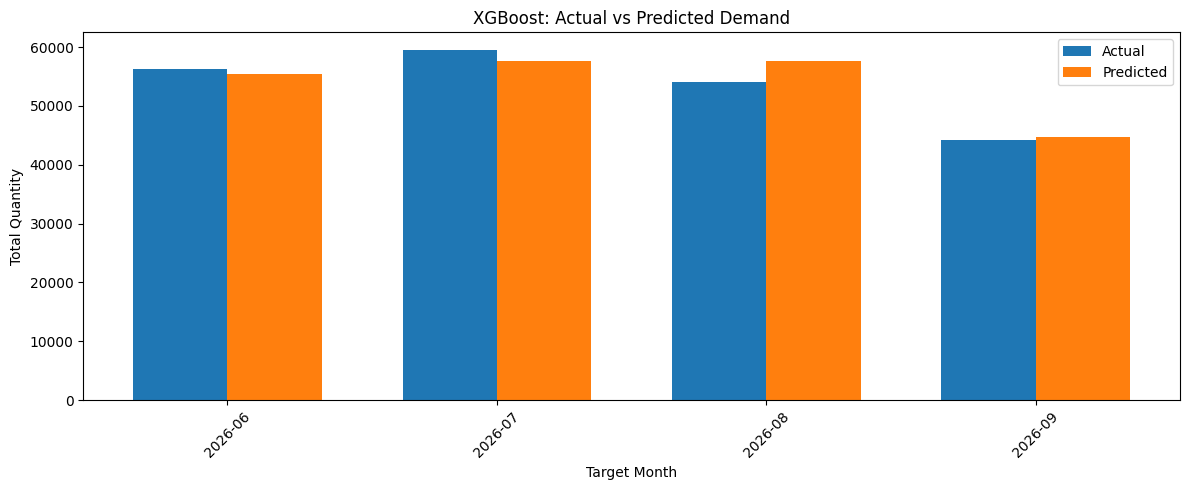


Sample SKU-Level Backtest Results


,SKU,Target_Month,Actual_Quantity,Predicted_Quantity
0,26115-1,2026-06,1144.0,1182.659546
1,26115-2,2026-06,2281.0,1381.912598
2,26115-3,2026-06,1292.0,680.297974
3,26115-4,2026-06,4303.0,2440.448730
4,26115-5,2026-06,1883.0,1377.399414
5,26115-6,2026-06,1598.0,1480.278442
6,26115-7,2026-06,1297.0,1250.514282
7,26115-8,2026-06,4016.0,2659.339355
8,CAT-013,2026-06,924.0,1035.886841
9,CAT-014,2026-06,1471.0,2097.564941


In [44]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# ==================================================
# 1. Generate walk-forward predictions
# ==================================================

backtest_results = []

for validation_month in validation_months:

    fold_train = model_data.loc[
        model_data["Target_Month"] < validation_month
    ].copy()

    fold_valid = model_data.loc[
        model_data["Target_Month"] == validation_month
    ].copy()

    if fold_train.empty or fold_valid.empty:
        continue

    fold_model = make_pipeline(best_params)

    fold_model.fit(
        fold_train[FEATURES],
        fold_train[TARGET]
    )

    predictions = np.maximum(
        fold_model.predict(fold_valid[FEATURES]),
        0
    )

    month_results = fold_valid[
        ["SKU", "Target_Month", TARGET]
    ].copy()

    month_results["Predicted_Quantity"] = predictions

    backtest_results.append(month_results)

if not backtest_results:
    raise ValueError("No backtest predictions were generated.")

backtest_df = pd.concat(
    backtest_results,
    ignore_index=True
)

backtest_df = backtest_df.rename(
    columns={TARGET: "Actual_Quantity"}
)

# ==================================================
# 2. Calculate overall metrics
# ==================================================

actual = backtest_df["Actual_Quantity"].to_numpy()
predicted = backtest_df["Predicted_Quantity"].to_numpy()

overall_mae = mean_absolute_error(actual, predicted)

total_absolute_error = np.abs(actual - predicted).sum()
total_actual_demand = np.abs(actual).sum()

overall_wape = (
    total_absolute_error / total_actual_demand * 100
    if total_actual_demand != 0
    else np.nan
)

print("Overall Backtesting Results")
print("-" * 35)
print(f"MAE:  {overall_mae:.3f}")
print(f"WAPE: {overall_wape:.2f}%")
print(f"Test rows: {len(backtest_df):,}")

# ==================================================
# 3. Monthly aggregate comparison
# ==================================================

monthly_evaluation = (
    backtest_df.groupby("Target_Month", as_index=False)
    .agg(
        Actual_Quantity=("Actual_Quantity", "sum"),
        Predicted_Quantity=("Predicted_Quantity", "sum")
    )
)

monthly_evaluation["Absolute_Error"] = np.abs(
    monthly_evaluation["Actual_Quantity"]
    - monthly_evaluation["Predicted_Quantity"]
)

monthly_evaluation["WAPE_%"] = np.where(
    monthly_evaluation["Actual_Quantity"].abs() > 0,
    monthly_evaluation["Absolute_Error"]
    / monthly_evaluation["Actual_Quantity"].abs() * 100,
    np.nan
)

print("\nMonthly Evaluation")
display(monthly_evaluation)

# ==================================================
# 4. Plot actual vs predicted monthly demand
# ==================================================

plot_data = monthly_evaluation.copy()
plot_data["Month"] = plot_data["Target_Month"].astype(str)

x = np.arange(len(plot_data))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_data["Actual_Quantity"],
    width,
    label="Actual"
)

plt.bar(
    x + width / 2,
    plot_data["Predicted_Quantity"],
    width,
    label="Predicted"
)

plt.xticks(x, plot_data["Month"], rotation=45)
plt.xlabel("Target Month")
plt.ylabel("Total Quantity")
plt.title("XGBoost: Actual vs Predicted Demand")
plt.legend()
plt.tight_layout()
plt.show()

# ==================================================
# 5. Inspect SKU-level predictions
# ==================================================

print("\nSample SKU-Level Backtest Results")
display(
    backtest_df.sort_values(
        ["Target_Month", "SKU"]
    ).head(20)
)


SKU-Level Forecasts


,SKU,Forecast_Month,Predicted_Quantity
0,26115-1,2026-10,285.443542
1,26115-1,2026-11,211.032883
2,26115-1,2026-12,336.941040
3,26115-2,2026-10,410.256195
4,26115-2,2026-11,329.160004
...,...,...,...
172,LEO-WC-P-5403,2026-11,168.830231
173,LEO-WC-P-5403,2026-12,387.189453
174,LEO-WC-P-5404,2026-10,352.254669
175,LEO-WC-P-5404,2026-11,551.688782



Monthly Demand Forecast


,Forecast_Month,Total_Predicted_Quantity,Number_of_SKUs
0,2026-10,37685.193344,59
1,2026-11,43427.427063,59
2,2026-12,54585.628143,59


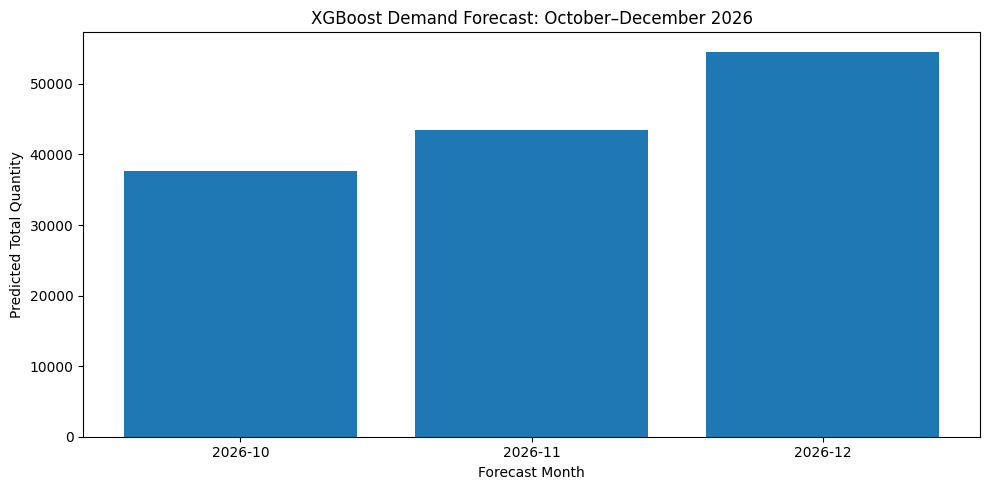

In [45]:

# ==================================================
# 1. Validate the forecasting horizon
# ==================================================

FORECAST_MONTHS = pd.period_range(
    start="2026-10",
    end="2026-12",
    freq="M"
)

if DATA_END != pd.Period("2026-09", freq="M"):
    raise ValueError(
        f"Expected actual data through September 2026, "
        f"but DATA_END is {DATA_END}. "
        "Check the requested forecast horizon before continuing."
    )

# ==================================================
# 2. Prepare one monthly history per SKU
# ==================================================

history_by_sku = {}

for sku, group in monthly_sku_data.groupby("SKU", sort=False):
    group = group.sort_values("Month")

    history_by_sku[sku] = group["Quantity"].astype(float).tolist()

# ==================================================
# 3. Recursive forecasting
# ==================================================

forecast_records = []

for forecast_month in FORECAST_MONTHS:

    current_month_predictions = []

    for sku, history in history_by_sku.items():

        if not history:
            continue

        # Features use the latest available month as the origin
        lag_1 = history[-1]
        lag_2 = history[-2] if len(history) >= 2 else np.nan
        lag_3 = history[-3] if len(history) >= 3 else np.nan
        lag_6 = history[-6] if len(history) >= 6 else np.nan
        lag_12 = history[-12] if len(history) >= 12 else np.nan

        rolling_mean_3 = np.mean(history[-3:])
        rolling_mean_6 = np.mean(history[-6:])

        rolling_std_3 = (
            np.std(history[-3:], ddof=1)
            if len(history[-3:]) >= 2
            else np.nan
        )

        same_month_last_year = (
            history[-12]
            if len(history) >= 12
            else np.nan
        )

        origin_month = forecast_month - 1
        origin_month_number = origin_month.month

        month_sin = np.sin(
            2 * np.pi * origin_month_number / 12
        )

        month_cos = np.cos(
            2 * np.pi * origin_month_number / 12
        )

        time_index = len(history) - 1

        input_row = pd.DataFrame([{
            "SKU": sku,
            "Lag_1": lag_1,
            "Lag_2": lag_2,
            "Lag_3": lag_3,
            "Lag_6": lag_6,
            "Lag_12": lag_12,
            "Rolling_Mean_3": rolling_mean_3,
            "Rolling_Mean_6": rolling_mean_6,
            "Rolling_Std_3": rolling_std_3,
            "Same_Month_Last_Year": same_month_last_year,
            "Month_Sin": month_sin,
            "Month_Cos": month_cos,
            "Time_Index": time_index
        }])

        predicted_quantity = max(
            float(final_sku_xgb_model.predict(input_row[FEATURES])[0]),
            0
        )

        current_month_predictions.append({
            "SKU": sku,
            "Forecast_Month": forecast_month,
            "Predicted_Quantity": predicted_quantity
        })

    # Save this month's forecasts
    forecast_records.extend(current_month_predictions)

    # Feed predictions into the history for the next month
    for record in current_month_predictions:
        history_by_sku[record["SKU"]].append(
            record["Predicted_Quantity"]
        )

# ==================================================
# 4. Build forecast output
# ==================================================

forecast_df = pd.DataFrame(forecast_records)

forecast_df["Forecast_Month"] = (
    forecast_df["Forecast_Month"].astype(str)
)

forecast_df = forecast_df.sort_values(
    ["SKU", "Forecast_Month"]
).reset_index(drop=True)

print("SKU-Level Forecasts")
display(forecast_df)

# ==================================================
# 5. Aggregate total forecast by month
# ==================================================

monthly_forecast = (
    forecast_df.groupby("Forecast_Month", as_index=False)
    .agg(
        Total_Predicted_Quantity=("Predicted_Quantity", "sum"),
        Number_of_SKUs=("SKU", "nunique")
    )
)

print("\nMonthly Demand Forecast")
display(monthly_forecast)

# ==================================================
# 6. Plot monthly total forecast
# ==================================================

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_forecast["Forecast_Month"],
    monthly_forecast["Total_Predicted_Quantity"]
)

plt.xlabel("Forecast Month")
plt.ylabel("Predicted Total Quantity")
plt.title("XGBoost Demand Forecast: October–December 2026")
plt.tight_layout()
plt.show()


In [46]:

import joblib
from pathlib import Path

# Create a separate directory for the XGBoost model
save_dir = Path("saved_models")
save_dir.mkdir(parents=True, exist_ok=True)

# Define the model artifact path
model_path = save_dir / "final_sku_xgboost_model.joblib"

# Save model and its configuration
model_artifact = {
    "model": final_sku_xgb_model,
    "best_params": best_params,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "target": TARGET,
    "data_start": str(DATA_START),
    "data_end": str(DATA_END),
    "forecast_months": [
        str(month) for month in FORECAST_MONTHS
    ],
    "model_type": "XGBRegressor",
    "selection_metric": "Mean_Walk_Forward_WAPE"
}

joblib.dump(model_artifact, model_path)

print("Final XGBoost model saved successfully.")
print(f"Model path: {model_path.resolve()}")
print(f"File size: {model_path.stat().st_size / 1024:.2f} KB")
print(f"Best parameters: {best_params}")


Final XGBoost model saved successfully.
Model path: D:\HVIA\task2\saved_models\final_sku_xgboost_model.joblib
File size: 345.15 KB
Best parameters: {'max_depth': 3, 'learning_rate': 0.03}
